# Linear Regression from Scratch (PyTorch)

Following [D2L Ch. 3 Linear Neural Networks for Regression](https://d2l.ai/chapter_linear-regression/index.html).

Linear regression is the simplest neural network: one layer, no activation. Implementing it by hand shows every piece that later models reuse — **data iterator, model, loss, optimizer, training loop**.

**Contents**
1. Generate a synthetic dataset with known weights
2. Implementation from scratch (only tensors + autograd)
3. Concise implementation with `torch.nn`
4. Closed-form solution, as a check

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lee2716/Dive_into_Deep_Learning_Code_Implementation/blob/main/linear_regression.ipynb)

In [1]:
import random
import torch
from torch import nn
import matplotlib.pyplot as plt

torch.manual_seed(0)
random.seed(0)

## 1. Synthetic Data

We create data from a model whose parameters we know, so we can check whether training recovers them:

$$\mathbf{y} = \mathbf{X}\mathbf{w} + b + \epsilon, \qquad \mathbf{w} = [2, -3.4]^\top,\ b = 4.2,\ \epsilon \sim \mathcal{N}(0, 0.01^2)$$

In [2]:
def synthetic_data(w, b, num_examples):
    """Generate y = Xw + b + noise."""
    X = torch.randn(num_examples, len(w))
    y = X @ w + b
    y += torch.normal(0, 0.01, y.shape)
    return X, y.reshape(-1, 1)

true_w = torch.tensor([2.0, -3.4])
true_b = 4.2
features, labels = synthetic_data(true_w, true_b, 1000)
print('features:', features[0], '\nlabel:', labels[0])

features: 


tensor([-1.1258, -1.1524]) 
label: tensor([5.8655])


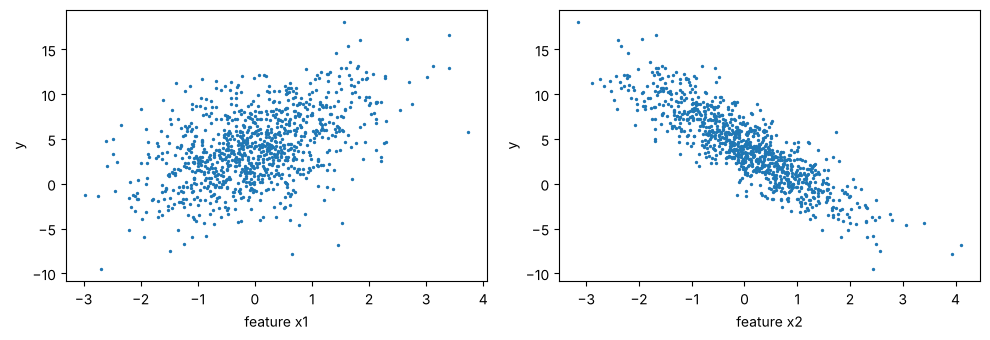

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for i, ax in enumerate(axes):
    ax.scatter(features[:, i], labels, s=2)
    ax.set_xlabel(f'feature x{i + 1}')
    ax.set_ylabel('y')
plt.tight_layout()
plt.show()

## 2. Implementation from Scratch

### Reading data in minibatches
Shuffle the indices once per epoch, then yield consecutive slices of size `batch_size`.

In [4]:
def data_iter(batch_size, features, labels):
    num_examples = len(features)
    indices = list(range(num_examples))
    random.shuffle(indices)
    for i in range(0, num_examples, batch_size):
        batch_indices = torch.tensor(indices[i: min(i + batch_size, num_examples)])
        yield features[batch_indices], labels[batch_indices]

batch_size = 10
X, y = next(data_iter(batch_size, features, labels))
print(X.shape, y.shape)

torch.Size([10, 2]) torch.Size([10, 1])


### Model, loss and optimizer

- **Model:** $\hat{y} = \mathbf{X}\mathbf{w} + b$
- **Loss:** squared error $\ell = \frac{1}{2}(\hat{y} - y)^2$ (the ½ makes the derivative cleaner)
- **Minibatch SGD:** $\theta \leftarrow \theta - \frac{\eta}{|\mathcal{B}|} \sum_{i \in \mathcal{B}} \nabla_\theta \ell^{(i)}$

Parameters start small and random; `requires_grad=True` tells autograd to track them.

In [5]:
w = torch.normal(0, 0.01, size=(2, 1), requires_grad=True)
b = torch.zeros(1, requires_grad=True)

def linreg(X, w, b):
    return X @ w + b

def squared_loss(y_hat, y):
    return (y_hat - y.reshape(y_hat.shape)) ** 2 / 2

def sgd(params, lr, batch_size):
    """Minibatch stochastic gradient descent (in place)."""
    with torch.no_grad():
        for param in params:
            param -= lr * param.grad / batch_size
            param.grad.zero_()

### Training loop
For each minibatch: forward pass → loss → `backward()` → parameter update.

In [6]:
lr, num_epochs = 0.03, 3
net, loss = linreg, squared_loss

for epoch in range(num_epochs):
    for X, y in data_iter(batch_size, features, labels):
        l = loss(net(X, w, b), y)
        l.sum().backward()
        sgd([w, b], lr, batch_size)
    with torch.no_grad():
        train_l = loss(net(features, w, b), labels)
        print(f'epoch {epoch + 1}, loss {train_l.mean():f}')

epoch 1, loss 0.039385
epoch 2, loss 0.000143
epoch 3, loss 0.000047


In [7]:
print(f'error in estimating w: {true_w - w.reshape(true_w.shape).detach()}')
print(f'error in estimating b: {true_b - b.item():.6f}')

error in estimating w: tensor([-9.0837e-05, -1.0216e-03])
error in estimating b: 0.000758


The learned parameters are very close to the true ones. 🎉

## 3. Concise Implementation

The same model with built-in PyTorch pieces:

| From scratch | `torch` equivalent |
|---|---|
| `data_iter` | `DataLoader(TensorDataset(...), shuffle=True)` |
| `linreg` | `nn.Linear(2, 1)` |
| `squared_loss` | `nn.MSELoss()` (no ½, averaged over the batch) |
| `sgd` | `torch.optim.SGD` |

In [8]:
from torch.utils.data import DataLoader, TensorDataset

loader = DataLoader(TensorDataset(features, labels), batch_size=10, shuffle=True)

net = nn.Linear(2, 1)
net.weight.data.normal_(0, 0.01)
net.bias.data.fill_(0)

loss_fn = nn.MSELoss()
optimizer = torch.optim.SGD(net.parameters(), lr=0.03)

for epoch in range(3):
    for X, y in loader:
        l = loss_fn(net(X), y)
        optimizer.zero_grad()
        l.backward()
        optimizer.step()
    with torch.no_grad():
        print(f'epoch {epoch + 1}, loss {loss_fn(net(features), labels):f}')

print('w:', net.weight.data, ' b:', net.bias.data)

epoch 1, loss 0.000241
epoch 2, loss 0.000094
epoch 3, loss 0.000093
w: tensor([[ 1.9999, -3.3997]])  b: tensor([4.1991])


## 4. Closed-Form Solution (Check)

Linear regression is one of the few models with an analytic solution. Appending a column of ones to $\mathbf{X}$ to absorb the bias:

$$\mathbf{w}^* = (\mathbf{X}^\top \mathbf{X})^{-1} \mathbf{X}^\top \mathbf{y}$$

`torch.linalg.lstsq` solves this in a numerically stable way.

In [9]:
X1 = torch.cat([features, torch.ones(len(features), 1)], dim=1)
solution = torch.linalg.lstsq(X1, labels).solution.flatten()
print('closed-form w:', solution[:2], ' b:', solution[2].item())

closed-form w: tensor([ 1.9999, -3.3997])  b: 4.199724197387695


## Exercises

1. What happens if you initialize the weights to zero? Does the algorithm still work? (For linear regression, yes — there is no symmetry to break.)
2. Try learning rates 0.001, 0.03, 1 and 3. Which ones converge, and how fast?
3. Replace the squared loss with `nn.HuberLoss()` and add a few large outliers to `labels`. Which loss is more robust?